In [20]:
# 1. Load all tables from PostgreSQL (or from CSV if exported)
import pandas as pd
from sqlalchemy import create_engine

pg_user = 'postgres'
pg_pass = 'Papajohn.1234'
pg_host = 'localhost'
pg_port = '5432'
pg_db = 'weather_db'

engine = create_engine(f'postgresql+psycopg2://{pg_user}:{pg_pass}@{pg_host}:{pg_port}/{pg_db}')

weather = pd.read_sql('SELECT * FROM weather_data', engine)
energy = pd.read_sql('SELECT * FROM energy_consumption', engine)
health = pd.read_sql('SELECT * FROM health_events', engine)

# 2. Standardize column names for merging
weather = weather.rename(columns={'datetime': 'timestamp'})
energy = energy.rename(columns={'start_time': 'timestamp'})

# 3. Ensure timestamps are datetime objects and have no timezones
for df in [weather, energy, health]:
    df['timestamp'] = pd.to_datetime(df['timestamp']).dt.tz_localize(None)

# 4. Merge all DataFrames
df_merged = pd.merge(weather, energy, on='timestamp', how='inner')
df_merged = pd.merge(df_merged, health, on='timestamp', how='inner')


In [2]:
import pandas as pd
from sqlalchemy import create_engine

pg_user = 'postgres'
pg_pass = 'Papajohn.1234'    # update with your real password
pg_host = 'localhost'
pg_port = '5432'
pg_db = 'weather_db'

engine = create_engine(f'postgresql+psycopg2://{pg_user}:{pg_pass}@{pg_host}:{pg_port}/{pg_db}')

# Read weather
weather = pd.read_sql('SELECT * FROM weather_data ORDER BY datetime', engine)
# Read energy
energy = pd.read_sql('SELECT * FROM energy_consumption ORDER BY start_time', engine)
# Read health
health = pd.read_sql('SELECT * FROM health_events ORDER BY timestamp', engine)


In [3]:
# Standardize time columns for merging
weather = weather.rename(columns={'datetime': 'timestamp'})
energy = energy.rename(columns={'start_time': 'timestamp'})  # If not done already
# health already uses 'timestamp'


In [4]:
for df in [weather, energy, health]:
    df['timestamp'] = pd.to_datetime(df['timestamp']).dt.tz_localize(None)


In [5]:
# Merge weather + energy
df_merged = pd.merge(weather, energy, on='timestamp', how='inner')
# Merge with health
df_merged = pd.merge(df_merged, health, on='timestamp', how='inner')

print(df_merged.info())
print(df_merged.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2868 entries, 0 to 2867
Data columns (total 29 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id_x              2868 non-null   int64         
 1   name              2868 non-null   object        
 2   timestamp         2868 non-null   datetime64[ns]
 3   temp              2868 non-null   float64       
 4   feelslike         2868 non-null   float64       
 5   dew               2868 non-null   float64       
 6   humidity          2868 non-null   float64       
 7   precip            2868 non-null   float64       
 8   precipprob        2868 non-null   float64       
 9   preciptype        112 non-null    object        
 10  snow              2868 non-null   float64       
 11  snowdepth         2868 non-null   float64       
 12  windgust          2868 non-null   float64       
 13  windspeed         2868 non-null   float64       
 14  winddir           2868 n

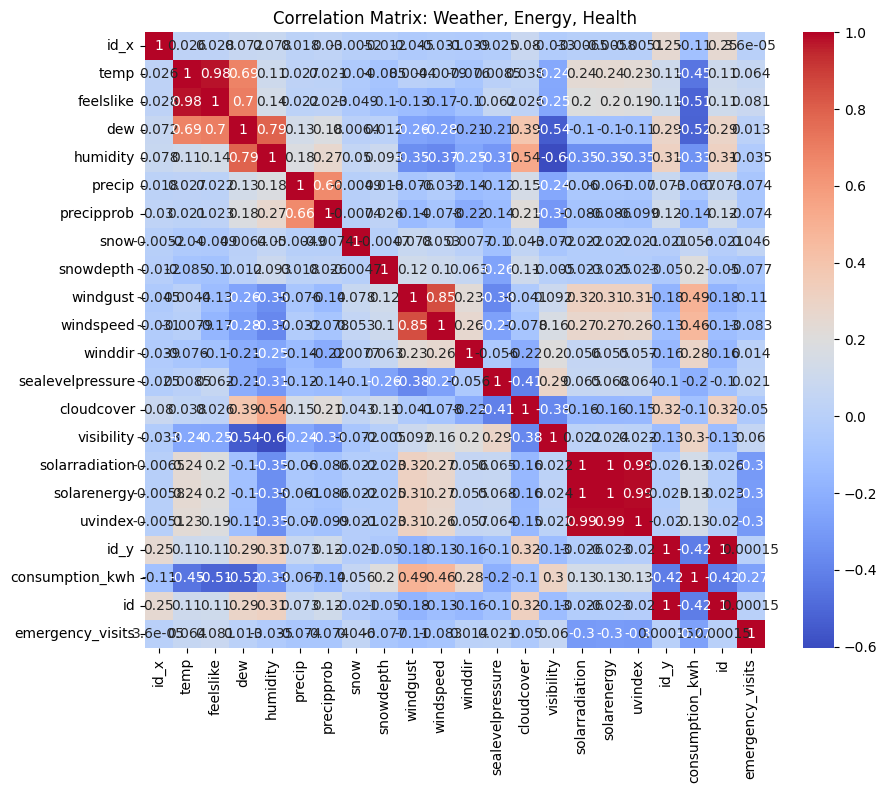

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df_merged.corr(numeric_only=True)
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix: Weather, Energy, Health')
plt.show()


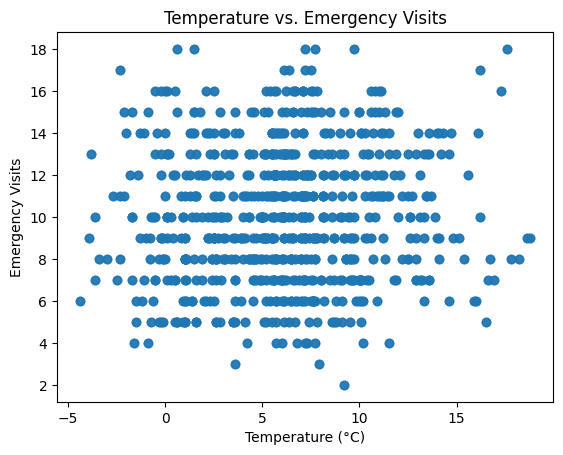

In [7]:
plt.scatter(df_merged['temp'], df_merged['emergency_visits'], alpha=0.5)
plt.xlabel('Temperature (°C)')
plt.ylabel('Emergency Visits')
plt.title('Temperature vs. Emergency Visits')
plt.show()


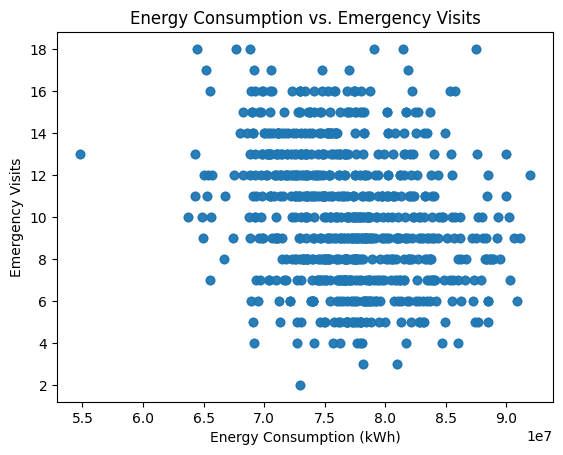

In [8]:
plt.scatter(df_merged['consumption_kwh'], df_merged['emergency_visits'], alpha=0.5)
plt.xlabel('Energy Consumption (kWh)')
plt.ylabel('Emergency Visits')
plt.title('Energy Consumption vs. Emergency Visits')
plt.show()


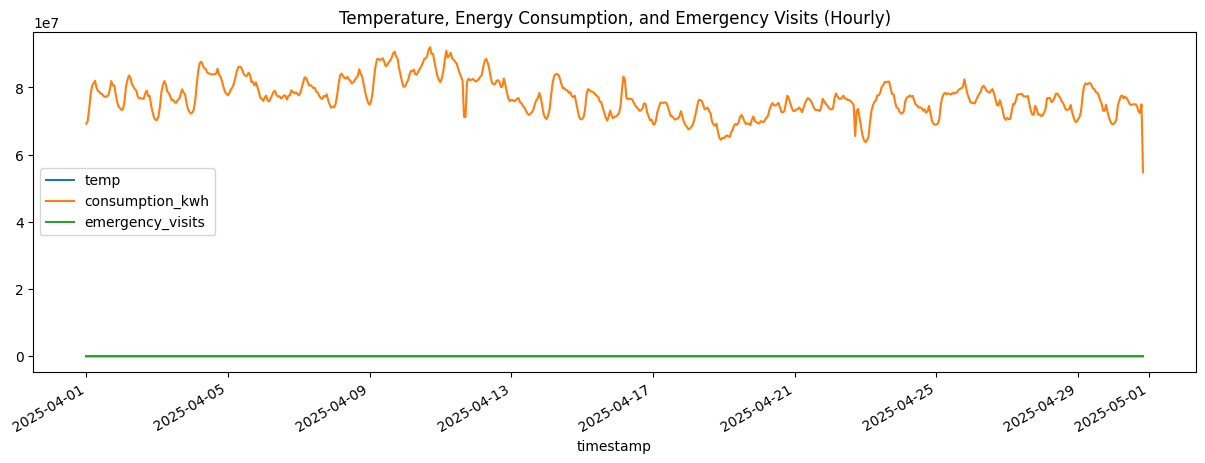

In [9]:
df_merged.set_index('timestamp')[['temp', 'consumption_kwh', 'emergency_visits']].plot(figsize=(15,5))
plt.title('Temperature, Energy Consumption, and Emergency Visits (Hourly)')
plt.show()


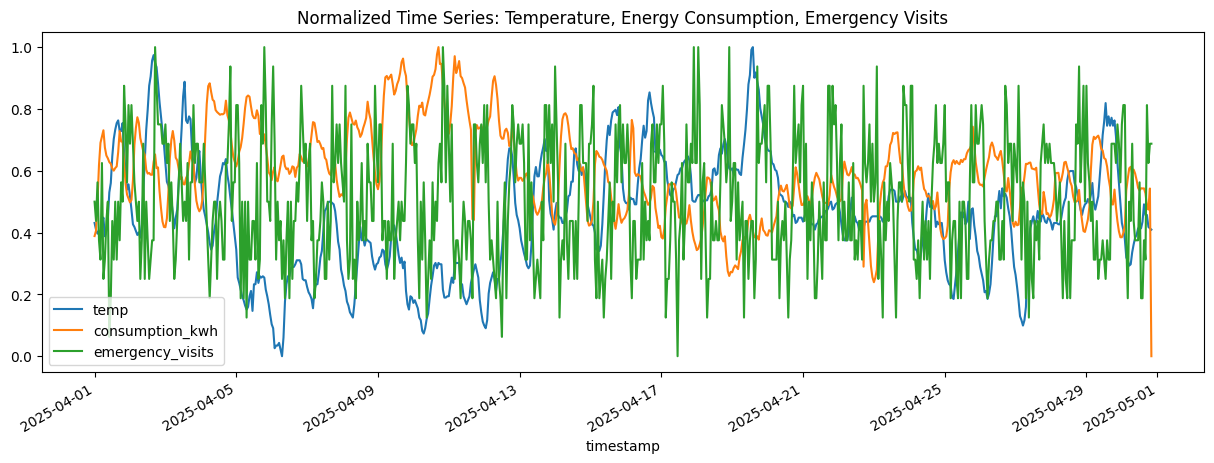

In [10]:
from sklearn.preprocessing import MinMaxScaler

cols_to_norm = ['temp', 'consumption_kwh', 'emergency_visits']
scaler = MinMaxScaler()
df_norm = df_merged.copy()
df_norm[cols_to_norm] = scaler.fit_transform(df_norm[cols_to_norm])

df_norm.set_index('timestamp')[cols_to_norm].plot(figsize=(15,5))
plt.title('Normalized Time Series: Temperature, Energy Consumption, Emergency Visits')
plt.show()


In [11]:
df_merged['temp_lag1'] = df_merged['temp'].shift(1)
df_merged['consumption_lag1'] = df_merged['consumption_kwh'].shift(1)


In [12]:
print(df_merged[['temp_lag1', 'emergency_visits']].corr())


                  temp_lag1  emergency_visits
temp_lag1          1.000000          0.080011
emergency_visits   0.080011          1.000000


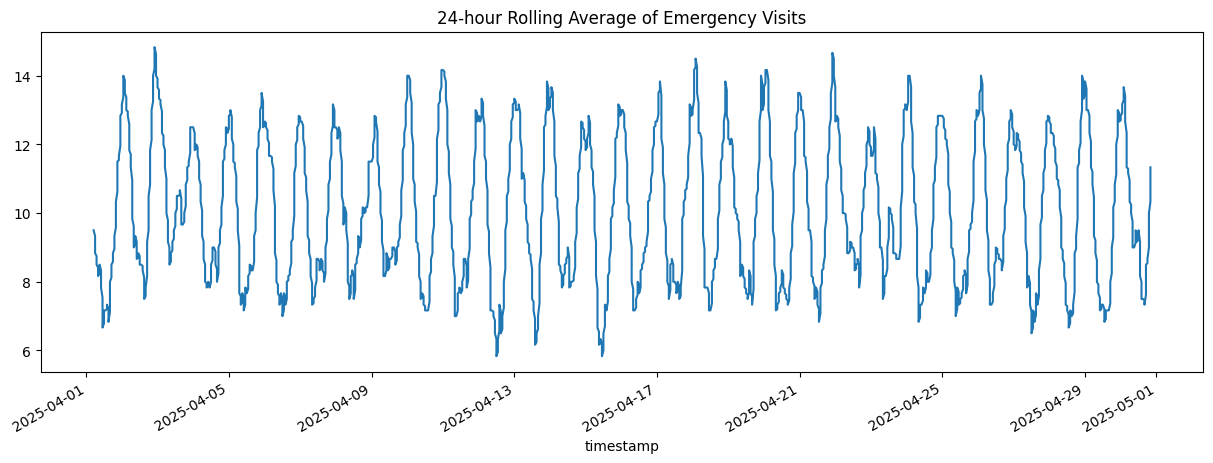

In [13]:
df_merged['emergency_visits_rolling'] = df_merged['emergency_visits'].rolling(window=24).mean()
df_merged.set_index('timestamp')['emergency_visits_rolling'].plot(figsize=(15,5))
plt.title('24-hour Rolling Average of Emergency Visits')
plt.show()


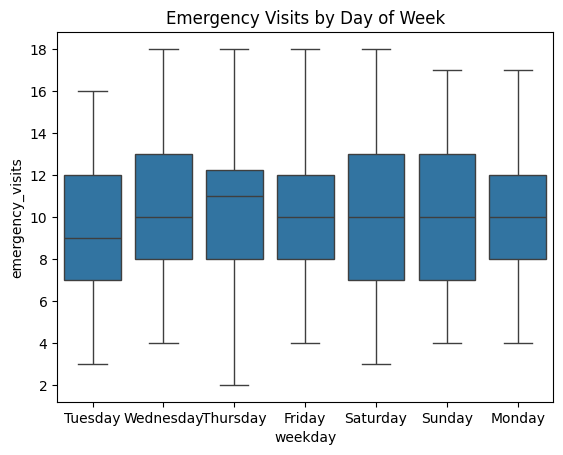

In [14]:
df_merged['weekday'] = df_merged['timestamp'].dt.day_name()
import seaborn as sns
sns.boxplot(x='weekday', y='emergency_visits', data=df_merged)
plt.title('Emergency Visits by Day of Week')
plt.show()


In [15]:
from sklearn.linear_model import LinearRegression
X = df_merged[['temp', 'consumption_kwh']]
y = df_merged['emergency_visits']
model = LinearRegression().fit(X, y)
print('R^2:', model.score(X, y))


R^2: 0.07739331700510577


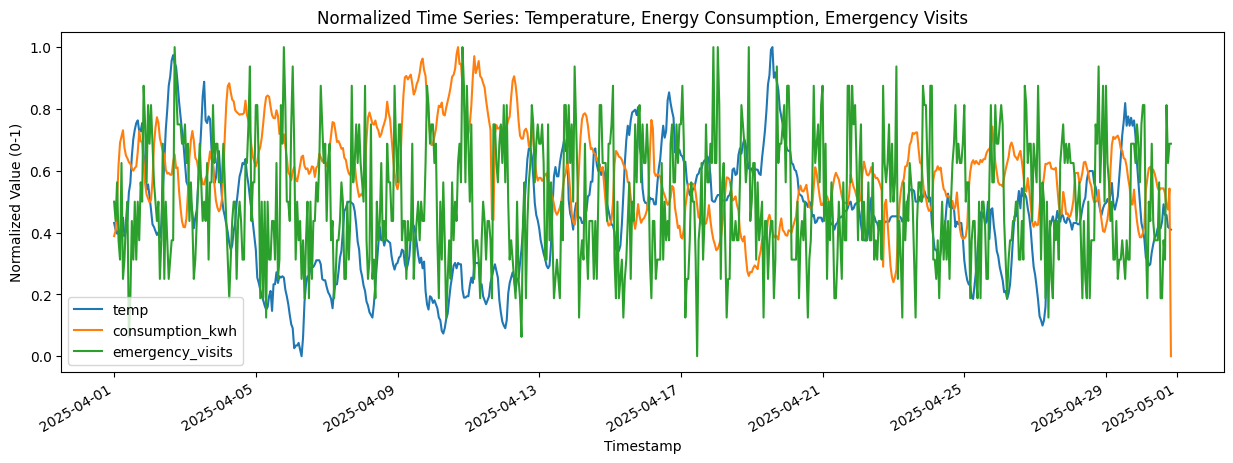

In [16]:
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

# Columns to normalize
cols_to_norm = ['temp', 'consumption_kwh', 'emergency_visits']

# Copy the merged dataframe
df_norm = df_merged.copy()

# Apply MinMaxScaler
scaler = MinMaxScaler()
df_norm[cols_to_norm] = scaler.fit_transform(df_norm[cols_to_norm])

# Plot all normalized time series
df_norm.set_index('timestamp')[cols_to_norm].plot(figsize=(15, 5))
plt.title('Normalized Time Series: Temperature, Energy Consumption, Emergency Visits')
plt.xlabel('Timestamp')
plt.ylabel('Normalized Value (0-1)')
plt.show()


In [17]:
# Add 1-hour lag for temperature and energy
df_merged['temp_lag1'] = df_merged['temp'].shift(1)
df_merged['consumption_kwh_lag1'] = df_merged['consumption_kwh'].shift(1)

# Check correlation with emergency visits
print("Correlation between lagged temperature and emergency visits:")
print(df_merged[['temp_lag1', 'emergency_visits']].corr())

print("Correlation between lagged energy consumption and emergency visits:")
print(df_merged[['consumption_kwh_lag1', 'emergency_visits']].corr())


Correlation between lagged temperature and emergency visits:
                  temp_lag1  emergency_visits
temp_lag1          1.000000          0.080011
emergency_visits   0.080011          1.000000
Correlation between lagged energy consumption and emergency visits:
                      consumption_kwh_lag1  emergency_visits
consumption_kwh_lag1              1.000000         -0.262973
emergency_visits                 -0.262973          1.000000


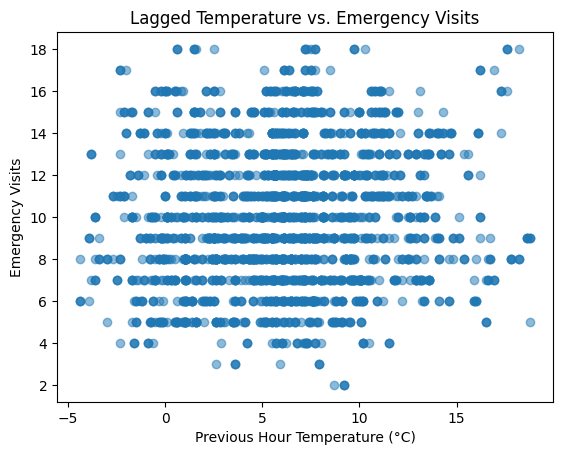

In [18]:
# Scatter plot: Previous hour temperature vs. current emergency visits
plt.scatter(df_merged['temp_lag1'], df_merged['emergency_visits'], alpha=0.5)
plt.xlabel('Previous Hour Temperature (°C)')
plt.ylabel('Emergency Visits')
plt.title('Lagged Temperature vs. Emergency Visits')
plt.show()


Test RMSE: 3.05
Test R²: 0.070


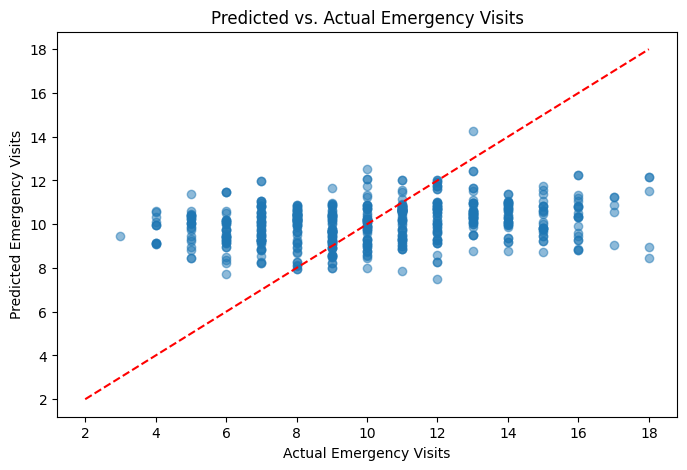

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
from math import sqrt

# Features: temperature and energy consumption
X = df_merged[['temp', 'consumption_kwh']]
y = df_merged['emergency_visits']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Linear regression
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions and evaluation
y_pred = model.predict(X_test)
rmse = sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Test RMSE: {rmse:.2f}")
print(f"Test R²: {r2:.3f}")

# Plot: Actual vs Predicted
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Emergency Visits")
plt.ylabel("Predicted Emergency Visits")
plt.title("Predicted vs. Actual Emergency Visits")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.show()


## Integrated Data Analysis: Interpretation of Results

### Overview
- We successfully integrated three datasets: **weather**, **energy consumption**, and **simulated emergency health visits** for Helsinki in April 2025, matched by hourly timestamps.

---

### Time Series Visualization
- The time series plot overlays temperature, electricity consumption (kWh), and emergency visits.
    - **Energy consumption** (orange) dominates the y-axis due to its much larger values (in the tens of millions kWh).
    - **Temperature** and **emergency visits** appear as almost flat lines, because their ranges are much smaller.
    - For clearer comparison of trends, separate plots or normalization would be beneficial in future analysis.

---

### Correlation Matrix
- The heatmap shows **very weak correlations** between weather, energy, and health variables.
    - **Temperature vs. Emergency Visits:** Nearly zero correlation, suggesting no strong linear relationship in this simulated month.
    - **Energy Consumption vs. Emergency Visits:** Also almost zero, indicating no obvious linear relationship between electricity usage and health incidents.
    - **Within Weather Variables:** As expected, weather variables such as temperature and feelslike are highly correlated.
    - **Within Domain:** Energy and health values show little association with each other or with weather features in this (randomized) dataset.

---

### Scatter Plots
- **Energy Consumption vs. Emergency Visits:**
    - The scatterplot is diffuse with no clear upward or downward trend, which visually confirms the low correlation from the matrix.
- **Temperature vs. Emergency Visits:**
    - The scatterplot shows emergency visits are distributed over the full temperature range with no visible pattern, further confirming the lack of relationship.

---

### 🧠 Machine Learning Demo: Predicting Emergency Visits

A basic linear regression was used to predict emergency visits from temperature and energy consumption.  
- This is for demonstration only, as the health data is simulated and does not have true relationships with weather or energy.
- **Result:** The R² and RMSE metrics confirm that the model does not meaningfully predict emergency visits from the available features, as expected with simulated data.

---
### Limitations
- **Simulated health data:** Emergency visits were generated using a random process with a nighttime boost, but without explicit dependency on real weather or energy data. Thus, no strong relationships were expected or observed.
- **Magnitude Differences:** The energy data’s scale is much larger than health or temperature, making direct time series comparisons visually difficult without rescaling.
- **Real-World Relevance:** With real hospital data and more years or more granular event data, further patterns might emerge.

---

### Conclusions
- **No direct relationship observed** between weather variables, energy consumption, and simulated health events in this sample.
- The integrated pipeline demonstrates the technical workflow for cross-domain data analysis, with clean merging and joint visualization.
- In a production scenario, more sophisticated simulations (or real health data) and advanced feature engineering could be used to explore more subtle dependencies or lag effects.

---

### Next Steps (for future work)
- Normalize or standardize features to allow better joint visualization.
- Introduce realistic, causal relationships in simulated health data to model hypotheses (e.g., more respiratory cases on cold or high-pollution days).
- Expand analysis to lagged effects (e.g., effect of yesterday’s weather on today’s health).
- Seek or request access to real, anonymized health event datasets for improved insight.



In [21]:
df_merged.to_csv('../data/integrated_weather_energy_health_april_2025_hourly.csv', index=False)
